# Experiment 4: Backbone freezing — training

RQ2. This notebook reuses the shared main factorial; it adds no training runs. Full and frozen backbones at both L2-SP levels remain in scope.

## 0. Evidence and scope

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, research_views as rv, choice_effects as ce
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
sink = FigureSaver('experiment4/01_training')
report = cp.NotebookReport('Experiment 4: Backbone freezing — training', sink=sink)
report.add('0. Evidence and scope', source_description() + '\nThe 512 unique main-grid runs support E1, E3 and E4. They are counted once. These comparisons are descriptive; tables, rather than folds or repeated recipes, are the averaging unit.')
runs = {track: cp.load_campaign(1, track) for track in ('pd', 'lgd')}

C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


## 1. Shared evidence and coverage

In [2]:
for track, run in runs.items():
    report.table(track.upper() + ': original factorial trial inventory', run.trials)
    report.table(track.upper() + ': planned four-cell coverage', run.trials.groupby(['base', 'frozen', 'l2sp_lambda']).size().rename('trials').reset_index())
report.add('1. Shared evidence and coverage', 'No factorial cell is dropped. A missing paired cell produces unavailable evidence, never an estimated zero.')

,trial_name,base,learning_rate,l2sp_lambda,frozen,sampling,seed,partition,min_train_rows,track,...,est_tflops,rows_seen,would_stop_epoch,source_file,source_row,split,attempt_count,evidence_status,base_short,lr_tag
0,cpt_main_v5_s00_pd_tabpfn-v2-classifier-v2_def...,TabPFN v2,3.000000e-07,0.000,False,one_sample,42,0,0,pd,...,2444.983394,84373151,2,cpt_main_v5_s00_pd.csv,6,0,1,recorded_only,v2-classifier-v2,3e-07
1,cpt_main_v5_s00_pd_tabpfn-v2-classifier-v2_def...,TabPFN v2,3.000000e-07,0.003,False,one_sample,42,0,0,pd,...,2444.983394,84373151,2,cpt_main_v5_s00_pd.csv,7,0,1,recorded_only,v2-classifier-v2,3e-07
2,cpt_main_v5_s00_pd_tabpfn-v2-classifier-v2_def...,TabPFN v2,3.000000e-07,0.000,True,one_sample,42,0,0,pd,...,1250.615968,84373151,2,cpt_main_v5_s00_pd.csv,4,0,1,recorded_only,v2-classifier-v2,3e-07
3,cpt_main_v5_s00_pd_tabpfn-v2-classifier-v2_def...,TabPFN v2,3.000000e-07,0.003,True,one_sample,42,0,0,pd,...,1250.615968,84373151,2,cpt_main_v5_s00_pd.csv,5,0,1,recorded_only,v2-classifier-v2,3e-07
4,cpt_main_v5_s00_pd_tabpfn-v2-classifier-v2_def...,TabPFN v2,1.000000e-06,0.000,False,one_sample,42,0,0,pd,...,2444.983394,84373151,2,cpt_main_v5_s00_pd.csv,17,0,1,recorded_only,v2-classifier-v2,1e-06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,cpt_main_v5_s03_pd_tabicl-classifier-v2-202602...,TabICLv2,1.000000e-05,0.003,True,one_sample,42,3,0,pd,...,11259.158116,191675495,12,cpt_main_v5_s03_pd.csv,69,3,2,recorded_only,tabicl-classifier-v2-20260212,1e-05
252,cpt_main_v5_s03_pd_tabicl-classifier-v2-202602...,TabICLv2,3.000000e-05,0.000,False,one_sample,42,3,0,pd,...,21124.367695,191675495,17,cpt_main_v5_s03_pd.csv,73,3,2,recorded_only,tabicl-classifier-v2-20260212,3e-05
253,cpt_main_v5_s03_pd_tabicl-classifier-v2-202602...,TabICLv2,3.000000e-05,0.003,False,one_sample,42,3,0,pd,...,21124.367695,191675495,42,cpt_main_v5_s03_pd.csv,75,3,2,recorded_only,tabicl-classifier-v2-20260212,3e-05
254,cpt_main_v5_s03_pd_tabicl-classifier-v2-202602...,TabICLv2,3.000000e-05,0.000,True,one_sample,42,3,0,pd,...,11259.158116,191675495,2,cpt_main_v5_s03_pd.csv,72,3,2,recorded_only,tabicl-classifier-v2-20260212,3e-05


,base,frozen,l2sp_lambda,trials
0,TabICLv2,False,0.000,16
1,TabICLv2,False,0.003,16
2,TabICLv2,True,0.000,16
3,TabICLv2,True,0.003,16
4,TabPFN v2,False,0.000,16
5,TabPFN v2,False,0.003,16
6,TabPFN v2,True,0.000,16
7,TabPFN v2,True,0.003,16
8,TabPFN v2.6,False,0.000,16
9,TabPFN v2.6,False,0.003,16


,trial_name,base,learning_rate,l2sp_lambda,frozen,sampling,seed,partition,min_train_rows,track,...,est_tflops,rows_seen,would_stop_epoch,source_file,source_row,split,attempt_count,evidence_status,base_short,lr_tag
0,cpt_main_v5_s00_lgd_tabpfn-v2-regressor-v2_def...,TabPFN v2,3.000000e-07,0.000,False,one_sample,42,0,0,lgd,...,2044.099860,46113629,2,cpt_main_v5_s00_lgd.csv,16,0,1,recorded_only,v2-regressor-v2,3e-07
1,cpt_main_v5_s00_lgd_tabpfn-v2-regressor-v2_def...,TabPFN v2,3.000000e-07,0.003,False,one_sample,42,0,0,lgd,...,2044.099860,46113629,2,cpt_main_v5_s00_lgd.csv,17,0,1,recorded_only,v2-regressor-v2,3e-07
2,cpt_main_v5_s00_lgd_tabpfn-v2-regressor-v2_def...,TabPFN v2,3.000000e-07,0.000,True,one_sample,42,0,0,lgd,...,1391.325658,46113629,2,cpt_main_v5_s00_lgd.csv,18,0,1,recorded_only,v2-regressor-v2,3e-07
3,cpt_main_v5_s00_lgd_tabpfn-v2-regressor-v2_def...,TabPFN v2,3.000000e-07,0.003,True,one_sample,42,0,0,lgd,...,1391.325658,46113629,2,cpt_main_v5_s00_lgd.csv,19,0,1,recorded_only,v2-regressor-v2,3e-07
4,cpt_main_v5_s00_lgd_tabpfn-v2-regressor-v2_def...,TabPFN v2,1.000000e-06,0.000,False,one_sample,42,0,0,lgd,...,2044.099860,46113629,2,cpt_main_v5_s00_lgd.csv,20,0,1,recorded_only,v2-regressor-v2,1e-06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,cpt_main_v5_s03_lgd_tabicl-regressor-v2-202602...,TabICLv2,1.000000e-05,0.003,True,one_sample,42,3,0,lgd,...,5794.130297,92356996,7,cpt_main_v5_s03_lgd.csv,42,3,1,recorded_only,tabicl-regressor-v2-20260212,1e-05
252,cpt_main_v5_s03_lgd_tabicl-regressor-v2-202602...,TabICLv2,3.000000e-05,0.000,False,one_sample,42,3,0,lgd,...,10545.317001,92356996,2,cpt_main_v5_s03_lgd.csv,44,3,1,recorded_only,tabicl-regressor-v2-20260212,3e-05
253,cpt_main_v5_s03_lgd_tabicl-regressor-v2-202602...,TabICLv2,3.000000e-05,0.003,False,one_sample,42,3,0,lgd,...,10545.317001,92356996,7,cpt_main_v5_s03_lgd.csv,46,3,1,recorded_only,tabicl-regressor-v2-20260212,3e-05
254,cpt_main_v5_s03_lgd_tabicl-regressor-v2-202602...,TabICLv2,3.000000e-05,0.000,True,one_sample,42,3,0,lgd,...,5794.130297,92356996,7,cpt_main_v5_s03_lgd.csv,45,3,1,recorded_only,tabicl-regressor-v2-20260212,3e-05


,base,frozen,l2sp_lambda,trials
0,TabICLv2,False,0.000,16
1,TabICLv2,False,0.003,16
2,TabICLv2,True,0.000,16
3,TabICLv2,True,0.003,16
4,TabPFN v2,False,0.000,16
5,TabPFN v2,False,0.003,16
6,TabPFN v2,True,0.000,16
7,TabPFN v2,True,0.003,16
8,TabPFN v2.6,False,0.000,16
9,TabPFN v2.6,False,0.003,16


## 2. Matched training trajectories

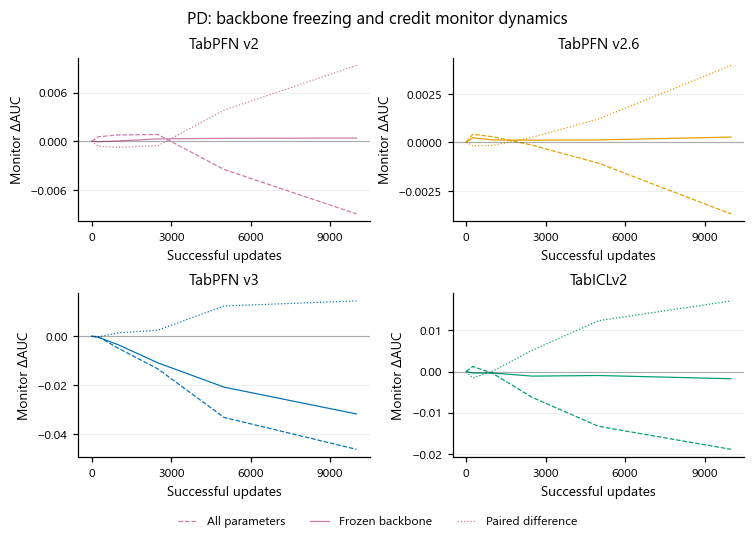

PD. Fixed-context credit monitoring trajectories for backbone freezing, matched within the remaining factorial settings. All parameters and Frozen backbone lines show improvement from update zero; the dotted line is the latter minus the former. Recipe pairs are averaged within table, then tables equally; only complete planned pairs contribute. These trajectories reuse the original factorial training records and do not replace the five-fold final benchmark. The results notebook additionally stratifies by the other factor and reports its interaction.

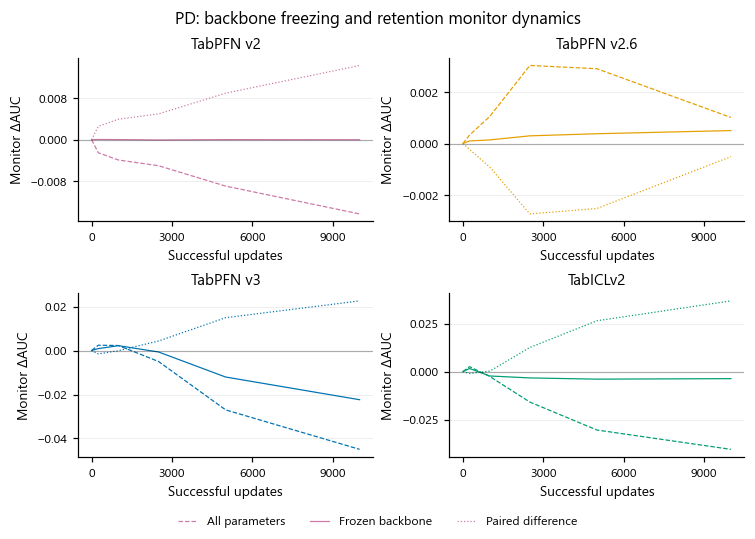

PD. Fixed-context retention monitoring trajectories for backbone freezing, matched within the remaining factorial settings. All parameters and Frozen backbone lines show improvement from update zero; the dotted line is the latter minus the former. Recipe pairs are averaged within table, then tables equally; only complete planned pairs contribute. These trajectories reuse the original factorial training records and do not replace the five-fold final benchmark. The results notebook additionally stratifies by the other factor and reports its interaction.

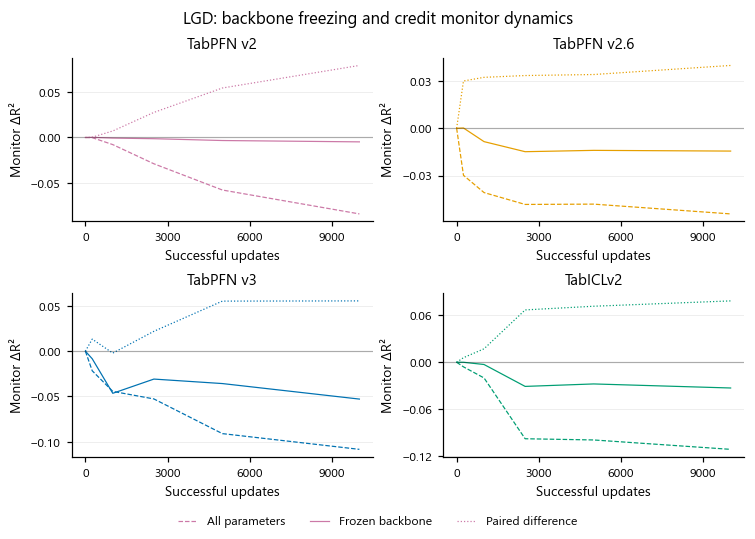

LGD. Fixed-context credit monitoring trajectories for backbone freezing, matched within the remaining factorial settings. All parameters and Frozen backbone lines show improvement from update zero; the dotted line is the latter minus the former. Recipe pairs are averaged within table, then tables equally; only complete planned pairs contribute. These trajectories reuse the original factorial training records and do not replace the five-fold final benchmark. The results notebook additionally stratifies by the other factor and reports its interaction.

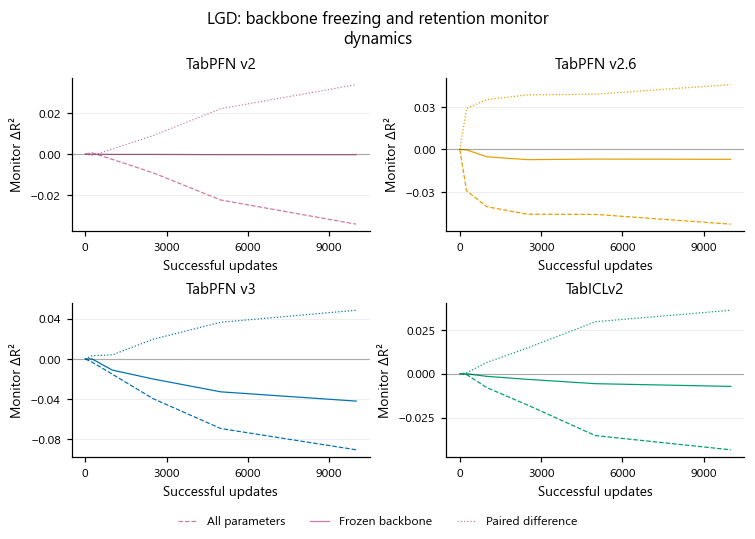

LGD. Fixed-context retention monitoring trajectories for backbone freezing, matched within the remaining factorial settings. All parameters and Frozen backbone lines show improvement from update zero; the dotted line is the latter minus the former. Recipe pairs are averaged within table, then tables equally; only complete planned pairs contribute. These trajectories reuse the original factorial training records and do not replace the five-fold final benchmark. The results notebook additionally stratifies by the other factor and reports its interaction.

In [3]:
for track, run in runs.items():
    cp.show(sink, rv.plot_factor_training(run, 4), track=track)
report.add('2. Matched training trajectories', 'Reference and changed-choice trajectories average matched configurations within each table, then tables equally. Dotted differences are calculated from those same pairs. Monitoring is separate from final five-fold evaluation.')

## 3. Optimization and cost

In [4]:
from src.visualize import publication as pub
for track, run in runs.items():
    report.table(track.upper() + ': recorded diagnostics', cp.diagnostics(run))
    report.table(track.upper() + ': computational cost', pub.cost_summary(run))
report.add('3. Optimization and cost', 'These are reused measurements from the original factorial. They are not additional compute or independent repeated runs.')

,trial_name,base,learning_rate,l2sp_lambda,frozen,sampling,seed,partition,min_train_rows,track,...,evidence_status,base_short,lr_tag,training_seconds,compute_seconds,data_wait_seconds,amp_skipped_steps,data_skipped_steps,compute_fraction,data_wait_fraction
0,cpt_main_v5_s00_pd_tabpfn-v2-classifier-v2_def...,TabPFN v2,3.000000e-07,0.000,False,one_sample,42,0,0,pd,...,recorded_only,v2-classifier-v2,3e-07,5125.305870,5048.258357,77.047513,0,0,0.984967,0.015033
1,cpt_main_v5_s00_pd_tabpfn-v2-classifier-v2_def...,TabPFN v2,3.000000e-07,0.003,False,one_sample,42,0,0,pd,...,recorded_only,v2-classifier-v2,3e-07,5181.541156,5105.531462,76.009694,0,0,0.985331,0.014669
2,cpt_main_v5_s00_pd_tabpfn-v2-classifier-v2_def...,TabPFN v2,3.000000e-07,0.000,True,one_sample,42,0,0,pd,...,recorded_only,v2-classifier-v2,3e-07,4979.895065,4904.452165,75.442900,0,0,0.984851,0.015149
3,cpt_main_v5_s00_pd_tabpfn-v2-classifier-v2_def...,TabPFN v2,3.000000e-07,0.003,True,one_sample,42,0,0,pd,...,recorded_only,v2-classifier-v2,3e-07,4991.646304,4916.032709,75.613596,0,0,0.984852,0.015148
4,cpt_main_v5_s00_pd_tabpfn-v2-classifier-v2_def...,TabPFN v2,1.000000e-06,0.000,False,one_sample,42,0,0,pd,...,recorded_only,v2-classifier-v2,1e-06,5120.380930,5043.298553,77.082377,0,0,0.984946,0.015054
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,cpt_main_v5_s03_pd_tabicl-classifier-v2-202602...,TabICLv2,1.000000e-05,0.003,True,one_sample,42,3,0,pd,...,recorded_only,tabicl-classifier-v2-20260212,1e-05,5509.466536,5364.777181,144.689355,0,0,0.973738,0.026262
252,cpt_main_v5_s03_pd_tabicl-classifier-v2-202602...,TabICLv2,3.000000e-05,0.000,False,one_sample,42,3,0,pd,...,recorded_only,tabicl-classifier-v2-20260212,3e-05,5692.625665,5543.267753,149.357912,0,0,0.973763,0.026237
253,cpt_main_v5_s03_pd_tabicl-classifier-v2-202602...,TabICLv2,3.000000e-05,0.003,False,one_sample,42,3,0,pd,...,recorded_only,tabicl-classifier-v2-20260212,3e-05,5844.957031,5698.968159,145.988871,0,0,0.975023,0.024977
254,cpt_main_v5_s03_pd_tabicl-classifier-v2-202602...,TabICLv2,3.000000e-05,0.000,True,one_sample,42,3,0,pd,...,recorded_only,tabicl-classifier-v2-20260212,3e-05,5480.163758,5336.275891,143.887867,0,0,0.973744,0.026256


,"('elapsed_sec', 'count')","('elapsed_sec', 'median')","('elapsed_sec', 'min')","('elapsed_sec', 'max')","('sec_per_step', 'count')","('sec_per_step', 'median')","('sec_per_step', 'min')","('sec_per_step', 'max')","('peak_gpu_gb', 'count')","('peak_gpu_gb', 'median')",...,"('rows_seen', 'min')","('rows_seen', 'max')","('trainable_params', 'count')","('trainable_params', 'median')","('trainable_params', 'min')","('trainable_params', 'max')","('final_drift', 'count')","('final_drift', 'median')","('final_drift', 'min')","('final_drift', 'max')"
"('TabICLv2', False)",32,5880.051329,5388.954923,6227.217700,32,0.588005,0.538895,0.622722,32,27.1190,...,168231937,195157151,32,27552250.0,27552250,27552250,32,0.003687,0.001127,0.028629
"('TabICLv2', True)",32,5641.459922,5191.705577,5953.787302,32,0.564146,0.519171,0.595379,32,26.7075,...,168231937,195157151,32,1818106.0,1818106,1818106,32,0.006402,0.001463,0.042363
"('TabPFN v2', False)",32,4989.562487,4558.125119,5434.754171,32,0.498956,0.455813,0.543475,32,181.0705,...,74887937,84373151,32,7244554.0,7244554,7244554,32,0.004249,0.001053,0.028788
"('TabPFN v2', True)",32,4818.276219,4399.349810,5211.900758,32,0.481828,0.439935,0.521190,32,108.1805,...,74887937,84373151,32,166666.0,166666,166666,32,0.006800,0.001252,0.078394
"('TabPFN v2.6', False)",32,4264.081141,3931.728692,4570.578204,32,0.426408,0.393173,0.457058,32,128.4200,...,80721937,91297151,32,10732042.0,10732042,10732042,32,0.003833,0.000877,0.040765
"('TabPFN v2.6', True)",32,3799.214932,3556.330243,4103.147097,32,0.379921,0.355633,0.410315,32,80.4470,...,80721937,91297151,32,101386.0,101386,101386,32,0.001670,0.000229,0.015853
"('TabPFN v3', False)",32,5222.860977,4837.436067,5610.246155,32,0.522286,0.483744,0.561025,32,121.0455,...,168231937,195157151,32,53153136.0,53153136,53153136,32,0.006299,0.001484,0.052170
"('TabPFN v3', True)",32,4818.272543,4506.762127,5040.165402,32,0.481827,0.450676,0.504017,32,109.9990,...,168231937,195157151,32,1795440.0,1795440,1795440,32,0.006421,0.001305,0.037843


,trial_name,base,learning_rate,l2sp_lambda,frozen,sampling,seed,partition,min_train_rows,track,...,evidence_status,base_short,lr_tag,training_seconds,compute_seconds,data_wait_seconds,amp_skipped_steps,data_skipped_steps,compute_fraction,data_wait_fraction
0,cpt_main_v5_s00_lgd_tabpfn-v2-regressor-v2_def...,TabPFN v2,3.000000e-07,0.000,False,one_sample,42,0,0,lgd,...,recorded_only,v2-regressor-v2,3e-07,2144.159500,2034.655456,109.504044,0,0,0.948929,0.051071
1,cpt_main_v5_s00_lgd_tabpfn-v2-regressor-v2_def...,TabPFN v2,3.000000e-07,0.003,False,one_sample,42,0,0,lgd,...,recorded_only,v2-regressor-v2,3e-07,2202.615980,2094.815415,107.800565,0,0,0.951058,0.048942
2,cpt_main_v5_s00_lgd_tabpfn-v2-regressor-v2_def...,TabPFN v2,3.000000e-07,0.000,True,one_sample,42,0,0,lgd,...,recorded_only,v2-regressor-v2,3e-07,2067.195755,1958.897112,108.298643,0,0,0.947611,0.052389
3,cpt_main_v5_s00_lgd_tabpfn-v2-regressor-v2_def...,TabPFN v2,3.000000e-07,0.003,True,one_sample,42,0,0,lgd,...,recorded_only,v2-regressor-v2,3e-07,2076.249450,1966.739212,109.510237,0,0,0.947256,0.052744
4,cpt_main_v5_s00_lgd_tabpfn-v2-regressor-v2_def...,TabPFN v2,1.000000e-06,0.000,False,one_sample,42,0,0,lgd,...,recorded_only,v2-regressor-v2,1e-06,2159.031472,2051.618729,107.412743,0,0,0.950250,0.049750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,cpt_main_v5_s03_lgd_tabicl-regressor-v2-202602...,TabICLv2,1.000000e-05,0.003,True,one_sample,42,3,0,lgd,...,recorded_only,tabicl-regressor-v2-20260212,1e-05,2275.730247,2162.357915,113.372332,0,0,0.950182,0.049818
252,cpt_main_v5_s03_lgd_tabicl-regressor-v2-202602...,TabICLv2,3.000000e-05,0.000,False,one_sample,42,3,0,lgd,...,recorded_only,tabicl-regressor-v2-20260212,3e-05,2632.817777,2235.119499,397.698279,0,0,0.848946,0.151054
253,cpt_main_v5_s03_lgd_tabicl-regressor-v2-202602...,TabICLv2,3.000000e-05,0.003,False,one_sample,42,3,0,lgd,...,recorded_only,tabicl-regressor-v2-20260212,3e-05,3018.019105,2377.990581,640.028524,0,0,0.787931,0.212069
254,cpt_main_v5_s03_lgd_tabicl-regressor-v2-202602...,TabICLv2,3.000000e-05,0.000,True,one_sample,42,3,0,lgd,...,recorded_only,tabicl-regressor-v2-20260212,3e-05,2925.888253,2116.013288,809.874965,0,0,0.723204,0.276796


,"('elapsed_sec', 'count')","('elapsed_sec', 'median')","('elapsed_sec', 'min')","('elapsed_sec', 'max')","('sec_per_step', 'count')","('sec_per_step', 'median')","('sec_per_step', 'min')","('sec_per_step', 'max')","('peak_gpu_gb', 'count')","('peak_gpu_gb', 'median')",...,"('rows_seen', 'min')","('rows_seen', 'max')","('trainable_params', 'count')","('trainable_params', 'median')","('trainable_params', 'min')","('trainable_params', 'max')","('final_drift', 'count')","('final_drift', 'median')","('final_drift', 'min')","('final_drift', 'max')"
"('TabICLv2', False)",32,2276.071883,961.560047,3470.316446,32,0.227607,0.096156,0.347032,32,10.993,...,24755261,92356996,32,28544983.0,28544983,28544983,32,0.004610,0.001245,0.039761
"('TabICLv2', True)",32,2119.043170,867.936296,3391.145004,32,0.211904,0.086794,0.339115,32,10.582,...,24755261,92356996,32,2823127.0,2823127,2823127,32,0.008231,0.001635,0.055758
"('TabPFN v2', False)",32,2361.717630,1538.051174,2822.926711,32,0.236172,0.153805,0.282293,32,79.359,...,24755261,55679662,32,11081864.0,11081864,11081864,32,0.003816,0.000655,0.018744
"('TabPFN v2', True)",32,2240.936746,1466.558088,2688.054035,32,0.224094,0.146656,0.268805,32,47.736,...,24755261,55679662,32,4003976.0,4003976,4003976,32,0.002423,0.000259,0.033726
"('TabPFN v2.6', False)",32,3126.751230,1846.503835,3650.390853,32,0.312675,0.184650,0.365039,32,89.881,...,24755261,59013662,32,12854792.0,12854792,12854792,32,0.017804,0.003871,0.147133
"('TabPFN v2.6', True)",32,2757.451636,1535.985452,3148.595242,32,0.275745,0.153599,0.314860,32,56.925,...,24755261,59013662,32,2224136.0,2224136,2224136,32,0.029176,0.002876,0.353532
"('TabPFN v3', False)",32,2341.062530,1332.112761,3017.463288,32,0.234106,0.133211,0.301746,32,46.569,...,24755261,92356996,32,58274936.0,58274936,58274936,32,0.015303,0.002324,0.094542
"('TabPFN v3', True)",32,2029.083655,1133.990570,2403.997635,32,0.202908,0.113399,0.240400,32,35.573,...,24755261,92356996,32,6917240.0,6917240,6917240,32,0.016063,0.002040,0.191601


## Complete text summary

In [5]:
print(report.summary(sink))

Experiment 4: Backbone freezing — training

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
The 512 unique main-grid runs support E1, E3 and E4. They are counted once. These comparisons are descriptive; tables, rather than folds or repeated recipes, are the averaging unit.

1. Shared evidence and coverage
No factorial cell is dropped. A missing paired cell produces unavailable evidence, never an estimated zero.

Table: PD: original factorial trial inventory
CSV (first column: row index)
row,trial_name,base,learning_rate,l2sp_lambda,frozen,sampling,seed,partition,min_train_rows,track,base_checkpoint,use_lora,query_fraction,accumulate_grad_batches,n_train_datasets,n_test_datasets,final_ckpt_path,elapsed_sec,status,error,primary_metric_name,baseline_train_metric,baseline_test_metric,final_train_metric,final_test_metric,final_train_loss,secondary_metric_name